In [83]:
from functools import partial
from typing import Iterator

import jax.numpy as jnp
from jax import jit, value_and_grad, random, tree
from tqdm import tqdm

import matplotlib.pyplot as plt
import numpy as np

from pyDOE import *

# ENM 5310 Fall 2026: Coding Assignment 1

# Problem 1 (Change of Variables) [25 points]

Consider the two-dimensional random variable $z = (z_1, z_2)$ distributed as

$$
p(z_1,z_2) = \mathcal{N}\left(\left[\begin{matrix} 0 \\ 0 \end{matrix}\right],
\left[\begin{matrix} 1 & 0 \\ 0 & 1 \end{matrix}\right]\right).
$$

Also consider the transformations $z_1 = g_1(x_1) = x_1^3 - 6x_1^2 + 12x_1 - 8$ and $z_2 = g_2(x_2)=x_2+1$. 

1. Find the inverse mappings of $g_1$ and $g_2$
2. Generate $5000$ realizations for $(z_1,z_2)$ from $p(z_1,z_2)$
3. Compute the pairs $(x_1, x_2)$ from the inverse mapping
4. Maximize the log-likelihood of the $(x_1,x_2)$ observations to estimate the parameters of the forward mapping that transforms $p(z)$ into $p(x)$, assuming a polynomial basis for each as 

$$g_1(x_1) = a_1x_1^3 - a_2x_1^2+a_3x_1+a_4, \quad g_2(x_2) = b_1x_2 + b_2$$

Train using gradient descent with a learning rate of $0.001$ for $5000$ epochs. Initialize the parameters by perturbing the true values, $a = a_{\text{true}} + \epsilon_a$ and $b = b_{\text{true}} + \epsilon_b$, where each entry of $\epsilon_a, \epsilon_b \sim \mathcal{N}(0, \sigma^2)$ with $\sigma = 1.5$.

Report the estimated parameters, plot the loss curve as a function of steps along with the loss evaluated at the true parameters, and visualize $p(x)$ at each step.

**Note:** The polynomial $g_1$ is not constrained to be monotone. During training it can bend back on itself, at which point the change-of-variables formula no longer gives a valid density (it integrates to more than 1). The optimizer can then reach a loss *below* the loss at the true parameters while the parameters drift away from the true solution. **If** you observe this, it is expected behavior and not a bug. Comment on what you see in your results.


# Solution

In [77]:
# Define g and g_inv here
def g(x):
    z = jnp.zeros_like(x) 
    z = z.at[:,0].set(x[:,1]+1)
    z = z.at[:,1].set(x[:,0]**3 - 6*x[:,0]**2 + 12*x[:,0] - 8)
    return z

def g_inv(z):
    x = jnp.zeros_like(z)
    x = x.at[:,0].set(jnp.cbrt(z[:,0])+2)
    x = x.at[:,1].set(z[:,1]-1)
    return x

In [78]:
key = random.PRNGKey(1234)
key, z_key, init_key = random.split(key, 3)

a_true = jnp.array([1,6,12,-8])
b_true = jnp.array([1,1])

z = random.normal(z_key, (5000, 2))
x = g_inv(z)
print(z)
print(x)

[[-0.55197525 -2.2980688 ]
 [-0.5037557  -0.29798272]
 [ 1.148008   -0.55258536]
 ...
 [-2.3029604  -0.22744104]
 [ 0.11863535  0.47632468]
 [-0.8600399   0.06114908]]
[[ 1.1796991  -3.2980688 ]
 [ 1.2043171  -1.2979827 ]
 [ 3.0470843  -1.5525854 ]
 ...
 [ 0.67942774 -1.2274411 ]
 [ 2.4913654  -0.5236753 ]
 [ 1.0490167  -0.93885094]]


In [79]:
def loss_fn(params, batch):
    # jax.scipy.stats.multivariate_normal may be useful here
    # raise NotImplementedError("TODO: implement/fill in")
    a,b = params
    x = batch
    
    loss = (-jnp.log(2*jnp.pi)
        - 0.5*((a[0]*x[:,0]**3 - a[1]*x[:,0]**2 + a[2]*x[:,0] + a[3])**2 
        + (b[0]*x[:,1] + b[1])**2)
        + jnp.log(jnp.abs(b[0]*(3*a[0]*x[:,0]**2 - 2*a[1]*x[:,0] + a[2])))
        )

    return -jnp.mean(loss)

@partial(jit, static_argnums=(2,))
def step(params, batch, lr):
    loss, grads = value_and_grad(loss_fn)(params, batch)
    params = tree.map(lambda p, g: p - lr * g, params, grads)
    return params, loss
    # raise NotImplementedError("TODO: implement/fill in")

In [80]:
key1, key2 = random.split(init_key, 2)
params = a_true + 1.5 * random.normal(key1, (4,)), b_true + 1.5 * random.normal(key2, (2,))

losses = []
lr = 0.001
epochs = 5000

a_preds = [params[0]]
b_preds = [params[1]]

for epoch in tqdm(range(epochs)):
    params, loss = step(params, x, lr)
    losses.append(loss)

    a_pred, b_pred = params
    a_preds.append(a_pred)
    b_preds.append(b_pred)

100%|██████████| 5000/5000 [00:01<00:00, 3509.25it/s]


True: a = [ 1  6 12 -8]
Pred: a = [ 1.0201312  6.1447973 12.328086  -8.228902 ] 

True: b = [1 1]
Pred: b = [1.0409273 1.0507444]
(100, 100)
(100, 100)
(100, 100)
(100, 100)
(100, 100)
(100, 100)


<function matplotlib.pyplot.show(close=None, block=None)>

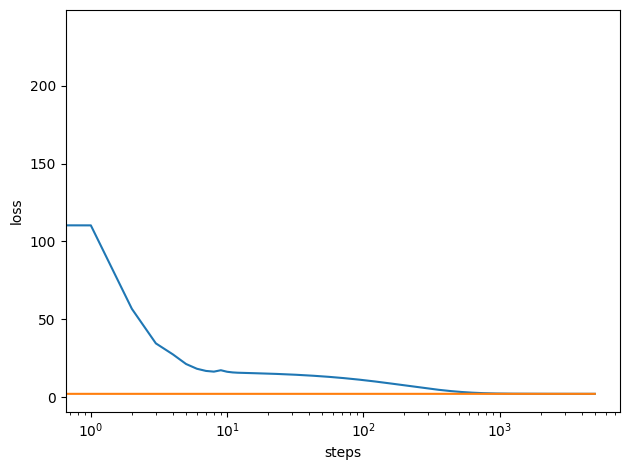

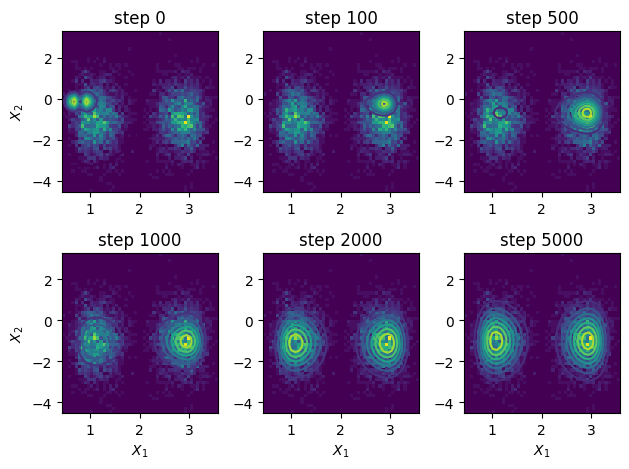

In [81]:
print("True: a =", a_true)
print("Pred: a =", a_pred, "\n")

print("True: b =", b_true)
print("Pred: b =", b_pred)

fig1, ax1 = plt.subplots()
ax1.plot(range(len(losses)),losses,label = "loss curve")
true_loss = loss_fn((a_true,b_true),x)
ax1.plot(range(len(losses)),jnp.full_like(jnp.array(losses),true_loss),label = "true loss")
ax1.set_xscale('log')
ax1.set_xlabel("steps")
ax1.set_ylabel("loss")
plt.tight_layout()


x1 = jnp.linspace(-4,4,100)
x2 = jnp.linspace(-4,4,100)
x1_contour, x2_contour = jnp.meshgrid(x1,x2)

step_plots = [0,100,500,1000,2000,5000]

fig2, ax2 = plt.subplots(2,3)
for i in range(6):
    row = i//3
    col = i%3
    a_pred = a_preds[step_plots[i]]
    b_pred = b_preds[step_plots[i]]
        
    ax2[row,col].hist2d(x[:,0],x[:,1],bins=50)

    z1 = a_pred[0]*x1_contour**3 - a_pred[1]*x1_contour**2 + a_pred[2]*x1_contour + a_pred[3]
    z2 = b_pred[0]*x2_contour + b_pred[1]

    p_z = 1/2*jnp.pi * jnp.exp(-1/2*(z1**2 + z2**2))
    J_g = jnp.abs(b_pred[0]*(3*a_pred[0]*x1_contour**2 - 2*a_pred[1]*x1_contour + a_pred[2]))

    p_x = p_z * J_g
    print(p_x.shape)
    ax2[row,col].contour(x1_contour,x2_contour,p_x)
    ax2[row,col].set_title(f"step {step_plots[i]}")
    
plt.setp(ax2[-1, :], xlabel=r"$X_1$") 
plt.setp(ax2[:, 0], ylabel = r"$X_2$") 
plt.tight_layout()
plt.show

# Problem 2 (Logistic Regression) [25 points]

Write a logistic regression model to classify the letters from the [EMNIST](https://www.nist.gov/itl/products-and-services/emnist-dataset) dataset.

1. Train your model to perform binary classification between the letters `a` and `b`. Plot the loss curve (on a log scale) and visualize performance on the training and test sets using a confusion matrix.

2. Train your model to perform binary classification between the letters `i` and `l`. Plot the loss curve (on a log scale) and visualize performance on the training and test sets using a confusion matrix.

3. Discuss the difference in accuracy between part 1 and part 2. Give an explanation to why this happens, what type of uncertainty does this corresponds to, and whether or not this is a limitation of logistic regression. 

4. Train your model to perform multiclass classification between `a`, `b`, `j` and `k`. Plot the loss curve (on a log scale) and visualize performance on the training and test sets using a confusion matrix.

Train each model using stochastic gradient descent with a learning rate of $0.05$ and batch size of $128$.

There are several ways to obtain the dataset, one way is through [torchvision](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.EMNIST.html) and another is to directly download it from [kaggle](https://www.kaggle.com/datasets/crawford/emnist). If you use kaggle, download and use `emnist-letters-train.csv` and `emnist-letters-test.csv`.

It is **always** a good idea to visualize your data (across many samples) and get familiar with it before you actually start to use it.

# Solution

In [4]:
train_data = np.loadtxt("emnist-letters-train.csv", delimiter=',')
test_data = np.loadtxt("emnist-letters-test.csv", delimiter=',')
mapping_data = np.loadtxt("emnist-letters-mapping.csv", delimiter=',')

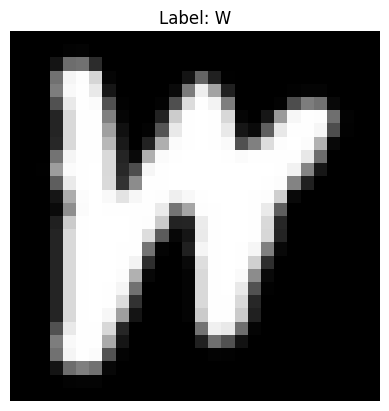

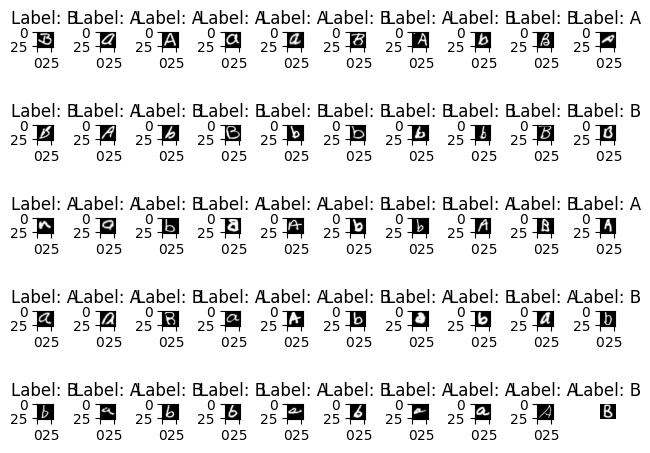

In [5]:
idx = 0

label = train_data[idx, 0]
ascii_label = chr(int(mapping_data[mapping_data[:,0] == label,1].item()))
image = train_data[idx, 1:].reshape(28, 28)

plt.imshow(image.T, cmap="gray")
plt.title(f"Label: {ascii_label}")
plt.axis("off")

n_print = 50
idx = ((train_data[:,0]==1) | (train_data[:,0]==2))
label = train_data[idx,0][:n_print]
image = train_data[idx,1:][:n_print]
fig, ax = plt.subplots(n_print//10, 10)
for i in range(len(label)):
    row = i//10
    col = i%10
    image_i = image[i].reshape(28, 28)
    label_i = label[i]
    ascii_label = chr(int(mapping_data[mapping_data[:,0] == label_i,1].item()))
    ax[row,col].imshow(image_i.T, cmap="gray")
    ax[row,col].set_title(f"Label: {ascii_label}")
    
plt.axis("off")
plt.tight_layout()

In [6]:
class Dataloader:
    def __init__(
        self,
        batch_size: int,
        n_examples: int,
        drop_last: bool = True,
        shuffle: bool = True,
    ):
        self.batch_size = batch_size
        self.n_examples = n_examples
        self.drop_last = drop_last
        self.shuffle = shuffle

        full, rest = divmod(n_examples, batch_size)
        self.n_batches = full if (drop_last or rest == 0) else full + 1
        self.limit = self.n_batches * self.batch_size if self.drop_last else self.n_examples

        if not self.shuffle: self.base_idx = jnp.arange(n_examples)

    def __len__(self) -> int:
        return self.n_batches

    def __call__(self, rng_key: jnp.ndarray = None) -> Iterator[jnp.ndarray]:
        if self.shuffle:
            idx = random.permutation(rng_key, self.n_examples)[: self.limit]
        else:
            idx = self.base_idx

        for start in range(0, self.limit, self.batch_size):
            yield idx[start : start + self.batch_size]

class Dataset:
    def __init__(self, inputs, labels):
        self.inputs = jnp.array(inputs)
        self.labels = jnp.array(labels).astype(jnp.float32)

    def get_batch(self, indices):
        return self.inputs[indices], self.labels[indices]

In [7]:
def predict_binary(params, inputs):
    # raise NotImplementedError("TODO: implement/fill in")
    a = inputs @ params
    sig_a = 1/(1+jnp.exp(-a))

    return sig_a

def loss_func_binary(params, inputs, labels):
    # raise NotImplementedError("TODO: implement/fill in")

    a = inputs @ params
    # sig_a = predict_binary(params,inputs)
    loss_matrix = jnp.maximum(a,0) + jnp.log(1+jnp.exp(-jnp.abs(a))) - labels*a
    # loss_matrix = -labels*jnp.log(predict_binary(params,inputs)) + (1-labels) * jnp.log(1-predict_binary(params,inputs))
    loss = jnp.mean(loss_matrix)

    return loss

@jit
def step_binary(params, inputs, labels, lr):
    # raise NotImplementedError("TODO: implement/fill in")
    loss, grads = value_and_grad(loss_func_binary)(params, inputs, labels)
    params = tree.map(lambda p, g: p - lr * g, params, grads)
    return params, loss

In [34]:
def predict_multi(params, inputs):
    # raise NotImplementedError("TODO: implement/fill in")
    a = inputs @ params
    softmax = jnp.exp(a)/jnp.sum(jnp.exp(a),axis = 1, keepdims = True)

    return softmax

def loss_func_multi(params, inputs, labels):
    # raise NotImplementedError("TODO: implement/fill in")

    p_nc = predict_multi(params, inputs)

    loss = -jnp.mean(jnp.sum(labels * jnp.log(p_nc), axis = 1))
    return loss

@jit
def step_multi(params, inputs, labels, lr):
    loss, grads = value_and_grad(loss_func_multi)(params, inputs, labels)
    params = tree.map(lambda p, g: p - lr * g, params, grads)
    return params, loss

# Part 1

In [68]:
n_classes = 2

idx = ((train_data[:,0]==1) | (train_data[:,0]==2))


train_inputs = train_data[idx,1:]/255
train_labels = (train_data[idx, 0] == 2).astype(jnp.float32)

params_key = random.PRNGKey(0)
params = random.normal(params_key, (784,1)) # use n_classes here

batch_size = 128
epochs = 1000
root_key = random.PRNGKey(1)

train_dataloader = Dataloader(batch_size=batch_size, n_examples=train_labels.shape[0])
train_dataset = Dataset(inputs=train_inputs, labels=train_labels[:,None])

losses = []
lr = 0.05

for epoch in tqdm(range(epochs)):
    for indices in train_dataloader(rng_key=random.fold_in(root_key, epoch)):
        inputs_batch, labels_batch = train_dataset.get_batch(indices)
        params, loss = step_binary(params, inputs_batch, labels_batch, lr)
        if np.isnan(params).any():
            print("nan detected")
            break
    losses.append(loss)

100%|██████████| 1000/1000 [01:28<00:00, 11.25it/s]


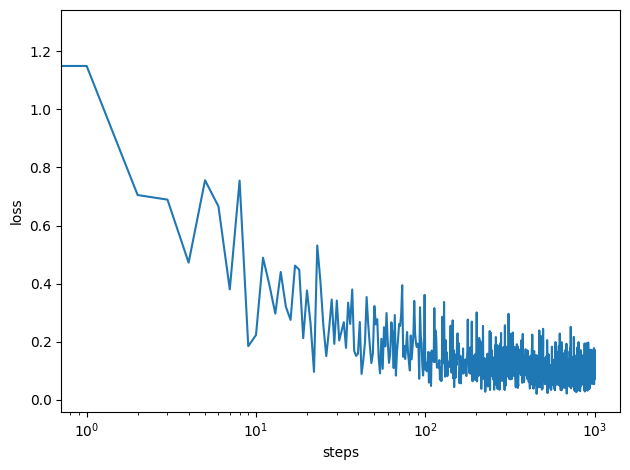

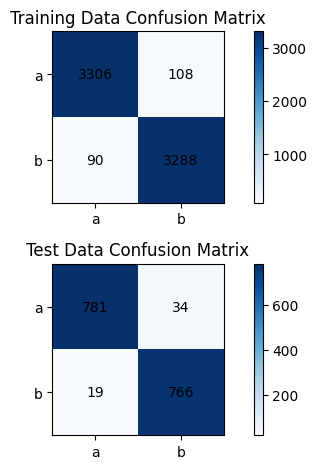

In [71]:
fig1, ax1 = plt.subplots()
ax1.plot(range(len(losses)),np.array(losses),label = "loss curve")
ax1.set_xscale('log')
ax1.set_xlabel("steps")
ax1.set_ylabel("loss")
plt.tight_layout()

test_idx = ((test_data[:,0]==1) | (test_data[:,0]==2))
test_image = test_data[test_idx,1:]/255
test_label = (test_data[test_idx, 0] == 2).astype(int)
p_test_label = predict_binary(params,test_image).ravel()
label_pred = (p_test_label >= 0.5).astype(int)

test_cm = np.array([[np.sum((label_pred == 0) & (test_label == 0)), np.sum((label_pred == 0) & (test_label == 1))],
              [np.sum((label_pred == 1) & (test_label == 0)), np.sum((label_pred == 1) & (test_label == 1))]])

train_idx = ((train_data[:,0]==1) | (train_data[:,0]==2))
train_image = train_data[train_idx,1:]/255
train_label = (train_data[train_idx, 0] == 2).astype(int)
p_train_label = predict_binary(params,train_image).ravel()
label_pred = (p_train_label >= 0.5).astype(int)

train_cm = np.array([[np.sum((label_pred == 0) & (train_label == 0)), np.sum((label_pred == 0) & (train_label == 1))],
              [np.sum((label_pred == 1) & (train_label == 0)), np.sum((label_pred == 1) & (train_label == 1))]])

# print(cm/len(label))

class_letters = ['a','b']

fig2, ax2 = plt.subplots(2,)

train_im = ax2[0].imshow(train_cm, cmap="Blues")
for i in range(train_cm.shape[0]):
    for j in range(train_cm.shape[1]):
        ax2[0].text(j, i, train_cm[i, j], ha="center", va="center")
fig2.colorbar(train_im,ax = ax2[0])
ax2[0].set_xticks(range(len(class_letters)), class_letters)
ax2[0].set_yticks(range(len(class_letters)), class_letters)
ax2[0].set_title('Training Data Confusion Matrix')

test_im = ax2[1].imshow(test_cm, cmap="Blues")
for i in range(test_cm.shape[0]):
    for j in range(test_cm.shape[1]):
        ax2[1].text(j, i, test_cm[i, j], ha="center", va="center")
fig2.colorbar(test_im,ax = ax2[1])
ax2[1].set_xticks(range(len(class_letters)), class_letters)
ax2[1].set_yticks(range(len(class_letters)), class_letters)
ax2[1].set_title('Test Data Confusion Matrix')
plt.tight_layout()

# Part 2

In [72]:
n_classes = 2

#i = 9, l = 12

idx = ((train_data[:,0]==9) | (train_data[:,0]==12))


train_inputs = train_data[idx,1:]/255
train_labels = (train_data[idx, 0] == 12).astype(jnp.float32)

params_key = random.PRNGKey(0)
params = random.normal(params_key, (784,1)) # use n_classes here

batch_size = 128
epochs = 1000
root_key = random.PRNGKey(1)

train_dataloader = Dataloader(batch_size=batch_size, n_examples=train_labels.shape[0])
train_dataset = Dataset(inputs=train_inputs, labels=train_labels[:,None])

losses = []
lr = 0.05

for epoch in tqdm(range(epochs)):
    for indices in train_dataloader(rng_key=random.fold_in(root_key, epoch)):
        inputs_batch, labels_batch = train_dataset.get_batch(indices)
        params, loss = step_binary(params, inputs_batch, labels_batch, lr)
        if np.isnan(params).any():
            print("nan detected")
            break
    losses.append(loss)

100%|██████████| 1000/1000 [01:30<00:00, 11.02it/s]


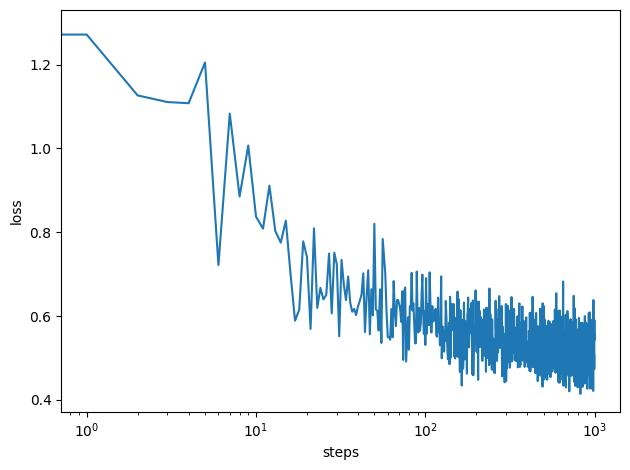

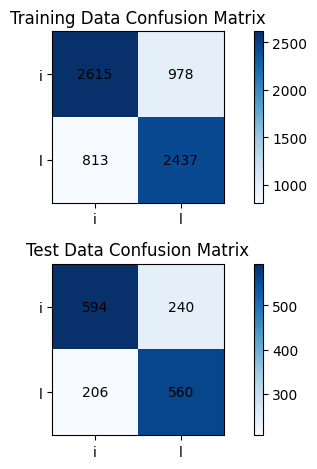

In [74]:
fig1, ax1 = plt.subplots()
ax1.plot(range(len(losses)),np.array(losses),label = "loss curve")
ax1.set_xscale('log')
ax1.set_xlabel("steps")
ax1.set_ylabel("loss")
plt.tight_layout()

test_idx = ((test_data[:,0]==9) | (test_data[:,0]==12))
test_image = test_data[test_idx,1:]/255
test_label = (test_data[test_idx, 0] == 12).astype(int)
p_test_label = predict_binary(params,test_image).ravel()
label_pred = (p_test_label >= 0.5).astype(int)

test_cm = np.array([[np.sum((label_pred == 0) & (test_label == 0)), np.sum((label_pred == 0) & (test_label == 1))],
              [np.sum((label_pred == 1) & (test_label == 0)), np.sum((label_pred == 1) & (test_label == 1))]])

train_idx = ((train_data[:,0]==9) | (train_data[:,0]==12))
train_image = train_data[train_idx,1:]/255
train_label = (train_data[train_idx, 0] == 12).astype(int)
p_train_label = predict_binary(params,train_image).ravel()
label_pred = (p_train_label >= 0.5).astype(int)

train_cm = np.array([[np.sum((label_pred == 0) & (train_label == 0)), np.sum((label_pred == 0) & (train_label == 1))],
              [np.sum((label_pred == 1) & (train_label == 0)), np.sum((label_pred == 1) & (train_label == 1))]])

# print(cm/len(label))

class_letters = ['i','l']

fig2, ax2 = plt.subplots(2,)

train_im = ax2[0].imshow(train_cm, cmap="Blues")
for i in range(train_cm.shape[0]):
    for j in range(train_cm.shape[1]):
        ax2[0].text(j, i, train_cm[i, j], ha="center", va="center")
fig2.colorbar(train_im,ax = ax2[0])
ax2[0].set_xticks(range(len(class_letters)), class_letters)
ax2[0].set_yticks(range(len(class_letters)), class_letters)
ax2[0].set_title('Training Data Confusion Matrix')

test_im = ax2[1].imshow(test_cm, cmap="Blues")
for i in range(test_cm.shape[0]):
    for j in range(test_cm.shape[1]):
        ax2[1].text(j, i, test_cm[i, j], ha="center", va="center")
fig2.colorbar(test_im,ax = ax2[1])
ax2[1].set_xticks(range(len(class_letters)), class_letters)
ax2[1].set_yticks(range(len(class_letters)), class_letters)
ax2[1].set_title('Test Data Confusion Matrix')
plt.tight_layout()

# Part 3
We can see in comparing part 1 vs part 2 that in the same amount of epochs that the logistic regression has a hard time identifying the difference between i and l in comparison to a vs b. this difference is largely epistemic, since this logistic regression strategy doesnt utilize context (like neighboring letters) or knowledge of specific font types. 

# Part 4

In [45]:
n_classes = 4

# a = 0, b = 1, j = 10, k = 11

class_ids = jnp.array([1,2,10,11])

train_idx = ((train_data[:,0]==class_ids[0]) | 
       (train_data[:,0]==class_ids[1]) | 
       (train_data[:,0]==class_ids[2]) | 
        (train_data[:,0]==class_ids[3]))

test_idx = ((test_data[:,0]==class_ids[0]) | 
       (test_data[:,0]==class_ids[1]) | 
       (test_data[:,0]==class_ids[2]) | 
        (test_data[:,0]==class_ids[3]))


N_train = len(train_data[train_idx,0])
N_test = len(test_data[test_idx,0])

train_inputs = train_data[train_idx,1:]/255
test_inputs = test_data[test_idx,1:]/255

train_labels_raw = train_data[train_idx,0]
train_labels = jnp.searchsorted(class_ids, train_labels_raw)

train_labels_onehot = jnp.zeros((N_train,n_classes))
train_labels_onehot = train_labels_onehot.at[
    jnp.arange(N_train),
    train_labels
    ].set(1)

test_labels_raw = test_data[test_idx,0]
test_labels = jnp.searchsorted(class_ids, test_labels_raw)

test_labels_onehot = jnp.zeros((N_test,n_classes))
test_labels_onehot = test_labels_onehot.at[
    jnp.arange(N_test),
    test_labels
    ].set(1)

params_key = random.PRNGKey(0)
params = random.normal(params_key,(784,n_classes)) # use n_classes here

batch_size = 128
epochs = 1000
root_key = random.PRNGKey(1)

train_dataloader = Dataloader(batch_size=batch_size, n_examples=train_labels_onehot.shape[0])
train_dataset = Dataset(inputs=train_inputs, labels=train_labels_onehot)

losses = []
lr = 0.05

for epoch in tqdm(range(epochs)):
    for indices in train_dataloader(rng_key=random.fold_in(root_key, epoch)):
        inputs_batch, labels_batch = train_dataset.get_batch(indices)
        params, loss = step_multi(params, inputs_batch, labels_batch, lr)
    losses.append(loss)

100%|██████████| 1000/1000 [03:27<00:00,  4.83it/s]


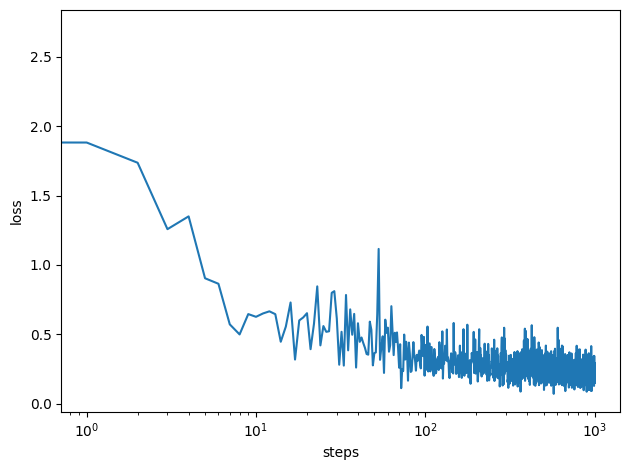

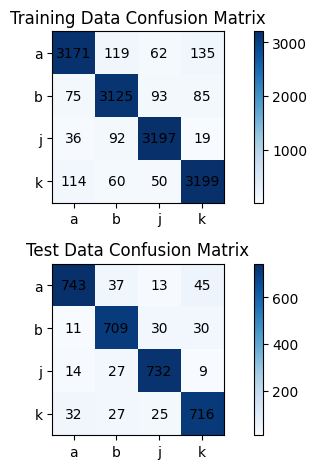

In [59]:
fig1, ax1 = plt.subplots()
ax1.plot(range(len(losses)),np.array(losses),label = "loss curve")
ax1.set_xscale('log')
ax1.set_xlabel("steps")
ax1.set_ylabel("loss")
plt.tight_layout()

test_image = test_data[test_idx,1:]/255
p_label = predict_multi(params,test_image)
label_pred = jnp.argmax(p_label,axis = 1)

test_cm = np.array([[np.sum((label_pred == 0) & (test_labels == 0)), np.sum((label_pred == 0) & (test_labels == 1)), np.sum((label_pred == 0) & (test_labels == 2)), np.sum((label_pred == 0) & (test_labels == 3))],
              [np.sum((label_pred == 1) & (test_labels == 0)), np.sum((label_pred == 1) & (test_labels == 1)), np.sum((label_pred == 1) & (test_labels == 2)), np.sum((label_pred == 1) & (test_labels == 3))],
              [np.sum((label_pred == 2) & (test_labels == 0)), np.sum((label_pred == 2) & (test_labels == 1)), np.sum((label_pred == 2) & (test_labels == 2)), np.sum((label_pred == 2) & (test_labels == 3))],
              [np.sum((label_pred == 3) & (test_labels == 0)), np.sum((label_pred == 3) & (test_labels == 1)), np.sum((label_pred == 3) & (test_labels == 2)), np.sum((label_pred == 3) & (test_labels == 3))]])


train_image = train_data[train_idx,1:]/255
p_label = predict_multi(params,train_image)
label_pred = jnp.argmax(p_label,axis = 1)

train_cm = np.array([[np.sum((label_pred == 0) & (train_labels == 0)), np.sum((label_pred == 0) & (train_labels == 1)), np.sum((label_pred == 0) & (train_labels == 2)), np.sum((label_pred == 0) & (train_labels == 3))],
              [np.sum((label_pred == 1) & (train_labels == 0)), np.sum((label_pred == 1) & (train_labels == 1)), np.sum((label_pred == 1) & (train_labels == 2)), np.sum((label_pred == 1) & (train_labels == 3))],
              [np.sum((label_pred == 2) & (train_labels == 0)), np.sum((label_pred == 2) & (train_labels == 1)), np.sum((label_pred == 2) & (train_labels == 2)), np.sum((label_pred == 2) & (train_labels == 3))],
              [np.sum((label_pred == 3) & (train_labels == 0)), np.sum((label_pred == 3) & (train_labels == 1)), np.sum((label_pred == 3) & (train_labels == 2)), np.sum((label_pred == 3) & (train_labels == 3))]])


# print(test_cm/len(test_labels))

class_letters = ['a','b','j','k']

fig2, ax2 = plt.subplots(2,)

train_im = ax2[0].imshow(train_cm, cmap="Blues")
for i in range(train_cm.shape[0]):
    for j in range(train_cm.shape[1]):
        ax2[0].text(j, i, train_cm[i, j], ha="center", va="center")
fig2.colorbar(train_im,ax = ax2[0])
ax2[0].set_xticks(range(len(class_letters)), class_letters)
ax2[0].set_yticks(range(len(class_letters)), class_letters)
ax2[0].set_title('Training Data Confusion Matrix')

test_im = ax2[1].imshow(test_cm, cmap="Blues")
for i in range(test_cm.shape[0]):
    for j in range(test_cm.shape[1]):
        ax2[1].text(j, i, test_cm[i, j], ha="center", va="center")
fig2.colorbar(test_im,ax = ax2[1])
ax2[1].set_xticks(range(len(class_letters)), class_letters)
ax2[1].set_yticks(range(len(class_letters)), class_letters)
ax2[1].set_title('Test Data Confusion Matrix')
plt.tight_layout()

# Problem 3 (Bayesian Linear Regression) [25 points]

Implement Bayesian linear regression with basis functions,

$$ p(y| x,w) = \mathcal{N}(y| w^{T}\phi(x),\alpha^{-1}I), \quad p(w)=\mathcal{N}(w| 0,\beta^{-1}I), \quad \alpha=5, \quad \beta = 0.1 $$

Generate a set of $N$ noisy observations by sampling

$$y(x) = e^x \sin(2\pi x) + \epsilon, \quad \epsilon\sim\mathcal{N}(0,0.5), \quad x\in[0,2]$$


on a [latin hypercube](https://pythonhosted.org/pyDOE/randomized.html) grid, and compute the MLE and MAP estimates for the weights $w$ using different types and numbers of features $\phi(x)$:
- Identity basis: $$ \phi(x) = x $$
- Monomial basis: $$ \phi(x) = \{1, x, x^2, x^3, \dots, x^M\} $$
- Fourier basis: $$ \phi(x) = \{0, 1, \sin(\pi x), \cos(\pi x), \sin(2\pi x), \cos(2\pi x), \dots, \sin(M\pi x), \cos(M\pi x)\} \quad (2M \text{ total features}) $$ 

Where $N=500$ and $M=4$. Plot the data, the mean predictions corresponding to the MLE and MAP estimates for $w$, and $500$ samples from the predictive posterior distribution.

# Monomial

In [148]:
key = random.PRNGKey(0)
key, MLE_key, MAP_key = random.split(key, 3)
N = 500
M = 4
D = M+1

x = 2*lhs(n=1,samples = N).flatten()
e = jnp.sqrt(0.5)*random.normal(key,(N,))
y = jnp.exp(x)*jnp.sin(2*jnp.pi*x)+e

alpha = 5
beta = 0.1

m_0 = jnp.zeros(D)
S_0 = 1/beta * jnp.eye(D)

phi = jnp.array([x**0,x**1,x**2,x**3,x**4]).T
S_Ninv = jnp.linalg.inv(S_0) + alpha * phi.T @ phi
S_N = jnp.linalg.inv(S_Ninv)
m_N = S_N @ (jnp.linalg.inv(S_0) @ m_0 + alpha * phi.T @ y)


(100, 500)


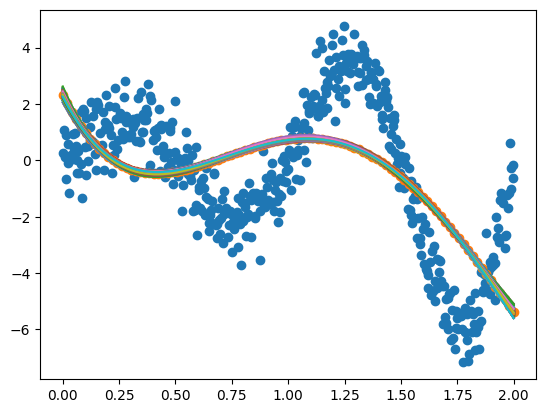

In [149]:
w = random.multivariate_normal(MAP_key,m_N,S_N,shape = (N,))
x_plot = jnp.linspace(0,2,100)
phi = jnp.array([x_plot**0,x_plot**1,x_plot**2,x_plot**3,x_plot**4]).T
f_MAP = phi @ w.T

print(f_MAP.shape)

plt.scatter(x,y)
plt.scatter(x_plot, phi @ m_N)
for i in range(N):
    plt.plot(x_plot, f_MAP[:,i])
    

# Fourier

In [145]:
key = random.PRNGKey(0)
key, MLE_key, MAP_key = random.split(key, 3)
N = 500
M = 4
D = 2*M+2

x = 2*lhs(n=1,samples = N).flatten()
e = jnp.sqrt(0.5)*random.normal(key,(N,))
y = jnp.exp(x)*jnp.sin(2*jnp.pi*x)+e

alpha = 5
beta = 0.1

m_0 = jnp.zeros(D)
S_0 = 1/beta * jnp.eye(D)

phi = jnp.array([jnp.zeros_like(x), jnp.ones_like(x), 
                 jnp.sin(jnp.pi*x), jnp.cos(jnp.pi*x), 
                 jnp.sin(2*jnp.pi*x), jnp.cos(2*jnp.pi*x), 
                 jnp.sin(3*jnp.pi*x), jnp.cos(3*jnp.pi*x),
                 jnp.sin(4*jnp.pi*x), jnp.cos(4*jnp.pi*x)]).T

S_Ninv = jnp.linalg.inv(S_0) + alpha * phi.T @ phi
S_N = jnp.linalg.inv(S_Ninv)
m_N = S_N @ (jnp.linalg.inv(S_0) @ m_0 + alpha * phi.T @ y)

(100, 500)


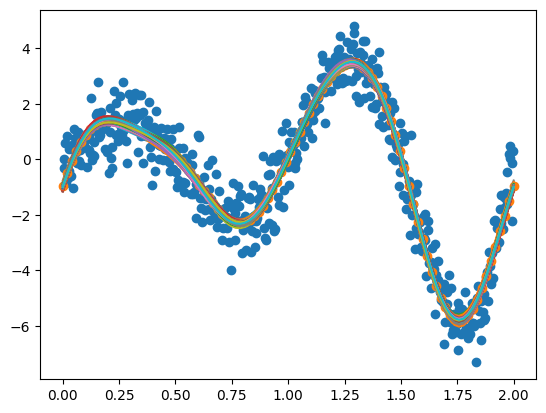

In [147]:
w = random.multivariate_normal(MAP_key,m_N,S_N,shape = (N,))
x_plot = jnp.linspace(0,2,100)
phi = jnp.array([jnp.zeros_like(x_plot), jnp.ones_like(x_plot), 
                 jnp.sin(jnp.pi*x_plot), jnp.cos(jnp.pi*x_plot), 
                 jnp.sin(2*jnp.pi*x_plot), jnp.cos(2*jnp.pi*x_plot), 
                 jnp.sin(3*jnp.pi*x_plot), jnp.cos(3*jnp.pi*x_plot),
                 jnp.sin(4*jnp.pi*x_plot), jnp.cos(4*jnp.pi*x_plot)]).T
f_MAP = phi @ w.T

print(f_MAP.shape)

plt.scatter(x,y)
plt.scatter(x_plot, phi @ m_N)
for i in range(N):
    plt.plot(x_plot, f_MAP[:,i])

# Problem 4 (Multi-fidelity Gaussian Processes) [25 points]

Implement a multi-fidelity Gaussian process regression code for approximating the "high-fidelity" Branin function with $X=(x,y)$

$$
f_{H}(X) = (y - (5.1 / (4\pi^2)) + (5 / \pi) x - 6)^2 + 10 (1 - (1 / (8\pi)))\cos(x) + 10,
$$

given observations generated by a "low-fidelity" function

$$
f_{L}(X) = 10 \sqrt{f_H(X - 2)} + 2 (x - 2.5) - 3 (3 y - 7) - 1.
$$

Specifically, generate a training data set consisting of $n_H=100$ high-fidelity observations of $f_{H}(x)$, and $n_L$ low-fidelity observations of $f_{L}(x)$ on a regular grid in $[-5,10] \times[0, 15]$ by utilizing latin-hypercube sampling. Train a multi-fidelity Gaussian process with a square exponential kernel to jointly predict both $f_{H}(x)$ and $f_{L}(x)$, and measure your relative prediction error against the exact solution in the $L^2$ norm for $n_L = 250, 450, 650, 850$.